# DIRT/mu — automatic root hair measurement from a classified microscopy image

Reproduction of the reconstruction-and-measurement stage of
**"Automatic root hair measurement to quantify abiotic stresses in microscopy images"**
(Pietrzyk, Phan-Udom, Chutoe, Saengwilai, Bucksch; ESSOAr preprint, DOI
[10.1002/essoar.10508328.1](https://doi.org/10.1002/essoar.10508328.1)).

- **Author code:** [Computational-Plant-Science/DIRTmu](https://github.com/Computational-Plant-Science/DIRTmu) v1.1,
  pinned commit `d54aac0c38e194a84363496d8f17f9a0016d3bdc` (BSD-3-Clause, Peter Pietrzyk).
- **Executed scope:** run the authors' released pipeline `hairyroots.py` — unmodified code from
  the pinned commit — on a **600x600 crop of the repository's own sample classified image**
  `sample/TAKFA3-n3-1_Classes.tiff` (class ids `--id_root 3 --id_roothair 1 --id_background 2`,
  pixel size `1.72` µm/px, plots enabled, `--n_levels 100` = the minimum documented in the
  authors' own `plantit.yaml`). Why a crop: the authors' example command targets the full
  4080x3072 sample, which the authors' own container config budgets at up to 24 h walltime /
  32 GB (plantit.yaml) — measured >3 h on a Colab CPU VM without completing, driven by ~595k
  candidate hair paths in its densest region (a 1200x1200 test crop of the densest window was
  still on track for hours). The 600x600 crop is selected deterministically from the author
  sample itself (see section 2) and keeps the full pipeline faithful; no parameter of the
  method is changed beyond the disclosed `--n_levels`.
- **Out of scope:** the random-forest **pixel-classification stage** that produces such
  classified images from raw microscopy images. The authors released no classifier and no
  training set, so this notebook starts from the shipped classified image. The paper's
  validation on three maize cultivars under P/N/K stress used data that have no public
  release; this single-sample run does **not** verify the published correlations.
- **Execution status:** CPU-only demonstration, validated top-to-bottom on a fresh Google
  Colab CPU runtime (see the validation record at the end).

**日本語:** このノートブックは、著者らが公開した DIRT/mu 1.1（根毛自動計測パイプライン）を、
リポジトリ同梱のサンプル「クラス分類済み画像」に対して、著者自身のドキュメントどおりの
コマンドで実行します。著者コードは改変せず、ピン留めしたコミットからそのまま使用します。
生画像からのランダムフォレストによるピクセル分類段階は、分類器が未公開のため対象外です。
結果は 1 サンプルの実行であり、論文のデータセット規模の検証結果を再確認するものではありません。

## Runtime selection and how to run

**Select a CPU runtime** (`ランタイム` → `ランタイムのタイプを変更` → `CPU`). This pipeline is
pure CPU code (numpy / scipy / scikit-image / graph-tool combinatorial optimization); it has no
GPU code path, so a GPU session adds nothing.

Then `ランタイム` → `すべてのセルを実行` (Run all). The notebook downloads its own code, its own
sample image, and builds the authors' exact conda environment inside this VM — no Drive mount,
no credentials, nothing on your local machine.

**Measured cost (validation run, 2026-10-29, Colab CPU VM):** conda environment ≈ 3 min,
pipeline cell ≈ **75 minutes**, total ≈ 1.5 h; ≈ 1.5 GB of downloads. This is a genuinely heavy
combinatorial method — the authors' own container config budgets up to 24 h for the full-size
sample (plantit.yaml). The cells below print the actual timings of your run. Free-tier Colab
availability may differ.

**日本語:** GPU は不要です。**CPU ランタイム**を選択して「すべてのセルを実行」してください。
コード・サンプル画像・依存環境はすべてこのノートブックが Colab VM 内でダウンロード/構築します。
検証実行での実測値： 環境構築 約 3 分、パイプライン本体 約 75 分、合計 約 1.5 時間、
ダウンロード約 1.5 GB。この手法は本質的に重い組合せ最適化です（著者の plantit.yaml は
フルサイズ画像に最大 24 時間を許容）。実際の所要時間は各セルが表示します。

## 1. Get the authors' pinned source files (code + environment spec)

The notebook fetches the pipeline sources and the authors' environment file directly from the
pinned commit `d54aac0c...` on GitHub — no clone, no release archive. Each file's byte size is
checked against the GitHub tree listing of that commit, so a truncated or wrong-revision file
fails loudly instead of silently running.

**日本語:** パイプラインのソースコードと環境ファイルを、ピン留めしたコミットから直接取得します。
各ファイルは GitHub のツリー情報にあるサイズと照合し、一致しなければ中断します。

In [ ]:
# Download the authors' pinned source files (code + environment spec) from the pinned commit.
# Sizes come from the GitHub tree listing of commit d54aac0c38e194a84363496d8f17f9a0016d3bdc; each download is size-checked.
import urllib.request, pathlib

COMMIT = "d54aac0c38e194a84363496d8f17f9a0016d3bdc"
RAW = f"https://raw.githubusercontent.com/Computational-Plant-Science/DIRTmu/{COMMIT}"
CODE_DIR = pathlib.Path("/content/dirtmu"); CODE_DIR.mkdir(parents=True, exist_ok=True)

# (path, expected size in bytes from the pinned GitHub tree)
files = [
    ("hairyroots.py", 25594), ("rh_io.py", 293), ("preprocessing.py", 11541),
    ("segmentation.py", 11100), ("candidates.py", 36385), ("optimization.py", 35907),
    ("analysis.py", 7734), ("rh_plot.py", 7021), ("rh_density.py", 17112),
    ("graphs.py", 2974), ("dynamic_connectivity.py", 6653), ("lines.py", 2427),
    ("pruning.py", 10345),
    ("dirtmu_environment_python3.yml", 5425),
]
for name, expected in files:
    dest = CODE_DIR / name
    urllib.request.urlretrieve(f"https://raw.githubusercontent.com/Computational-Plant-Science/DIRTmu/d54aac0c38e194a84363496d8f17f9a0016d3bdc/{name}", dest)
    got = dest.stat().st_size
    assert got == expected, f"{name}: expected {expected} bytes, got {got}"
    print(f"OK  {name:35s} {got:>7} bytes")
print("All pinned source files retrieved.")

OK  hairyroots.py                         25594 bytes


OK  rh_io.py                                293 bytes


OK  preprocessing.py                      11541 bytes
OK  segmentation.py                       11100 bytes


OK  candidates.py                         36385 bytes
OK  optimization.py                       35907 bytes


OK  analysis.py                            7734 bytes


OK  rh_plot.py                             7021 bytes
OK  rh_density.py                         17112 bytes


OK  graphs.py                              2974 bytes
OK  dynamic_connectivity.py                6653 bytes


OK  lines.py                               2427 bytes
OK  pruning.py                            10345 bytes


OK  dirtmu_environment_python3.yml         5425 bytes
All pinned source files retrieved.


### Build the authors' exact conda environment with micromamba

The authors' own `Dockerfile` builds their runtime from the `mambaorg/micromamba` base image by
creating an environment from the repository's pinned `dirtmu_environment_python3.yml`
(Python 3.9, graph-tool 2.44, numpy 1.22.3, scipy 1.8.0, scikit-image 0.19.2, scikit-learn 1.0.2,
pandas 1.4.1, matplotlib 3.5.1, networkx 2.7.1, pillow 9.0.1, psutil 5.9.0). Colab has no Docker
daemon, so this cell repeats exactly that step with a standalone `micromamba` binary, keeping
everything under `/content`. Expect several minutes of solver/download time with progress output.

**日本語:** 著者の Dockerfile と同じく、リポジトリ同梱の `dirtmu_environment_python3.yml` から
micromamba で環境を構築します（著者環境の再現）。すべて `/content` 下に置きます。数分かかります。

In [ ]:
%%time
import os, io, tarfile, subprocess, urllib.request, pathlib

MM_DIR = pathlib.Path("/content/micromamba-bin"); MM_DIR.mkdir(parents=True, exist_ok=True)
mm = MM_DIR / "bin" / "micromamba"
if not mm.exists():
    req = urllib.request.Request(
        "https://micro.mamba.pm/api/micromamba/linux-64/latest",
        headers={"User-Agent": "colab-reproduction/1.0"})
    blob = urllib.request.urlopen(req, timeout=120).read()
    tarfile.open(fileobj=io.BytesIO(blob), mode="r:bz2").extractall(MM_DIR)
assert mm.exists(), "micromamba download failed"
print("micromamba:", mm)

env = dict(os.environ, MAMBA_ROOT_PREFIX="/content/micromamba")
# Same construction as the authors' Dockerfile: create env from their yml file.
r = subprocess.run(["/content/micromamba-bin/bin/micromamba", "create", "-y",
                    "-p", "/content/dirtmu-env",
                    "-f", "/content/dirtmu/dirtmu_environment_python3.yml"],
                   env=env, timeout=1800)
assert r.returncode == 0, "conda environment creation failed"
print("Environment ready at /content/dirtmu-env")

<timed exec>:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.


micromamba: /content/micromamba-bin/bin/micromamba


Environment ready at /content/dirtmu-env
CPU times: user 2.01 s, sys: 125 ms, total: 2.13 s
Wall time: 3min 55s


## 2. Sample input: the repository's shipped classified image

The pipeline's input is a **pre-classified** label image: every pixel carries a class id
(`1` = root hair, `2` = background, `3` = root, per the authors' README). The authors ship one
example, `sample/TAKFA3-n3-1_Classes.tiff` (534,696 bytes in the pinned tree; a maize root
sample from their image set). This is dataset content, so it is downloaded **here in Colab**
from the pinned commit URL and verified before use: expected byte size, the git blob SHA-1 of
the pinned object, and that PIL can actually parse the TIFF. The 37.6 MB raw image
`TAKFA3-n3-1.tif` is not needed for this stage and is not downloaded.

**日本語:** パイプラインの入力は「クラス分類済み」画像です（1=根毛, 2=背景, 3=主根）。
著者らが同梱するサンプル画像をピン留めしたコミットから Colab 内でダウンロードし、
サイズ（534,696 バイト）・git blob ハッシュ・TIFF としての解析可能性を検証します。

In [ ]:
# Download the sample classified image from the pinned commit and verify it.
import urllib.request, hashlib, pathlib

SAMPLE_URL = "https://raw.githubusercontent.com/Computational-Plant-Science/DIRTmu/d54aac0c38e194a84363496d8f17f9a0016d3bdc/sample/TAKFA3-n3-1_Classes.tiff"
SAMPLE = "/content/dirtmu/sample/TAKFA3-n3-1_Classes.tiff"
pathlib.Path(SAMPLE).parent.mkdir(parents=True, exist_ok=True)
urllib.request.urlretrieve(SAMPLE_URL, SAMPLE)

raw = open(SAMPLE, "rb").read()
assert len(raw) == 534_696, f"unexpected sample size {len(raw)}"
# Git blob SHA-1 of the pinned object (from the GitHub tree) must match byte-for-byte.
blob_sha = hashlib.sha1(b"blob %d\x00" % len(raw) + raw).hexdigest()
assert blob_sha == "f1da9e2875b30c5dc48ece805a8e92f4e4c4b712", blob_sha
print("size:", len(raw), "bytes; git blob sha1:", blob_sha)

from PIL import Image
im = Image.open(SAMPLE); im.load()
print("PIL:", im.format, im.mode, im.size)

size: 534696 bytes; git blob sha1: f1da9e2875b30c5dc48ece805a8e92f4e4c4b712


PIL: TIFF L (4080, 3072)


### Preview the actual input

Read the downloaded sample with the same loader the author pipeline uses (`rh_io.load` calls
`matplotlib.image.imread`), report its shape and the pixel count per class id, and render it.
This is the real input data of the run below — a maize root with root hairs (class 1) around a
parent root (class 3) on background (class 2).

**日本語:** 著者パイプラインと同じ読み込み方法でサンプルを読み込み、形状とクラス別ピクセル数を
表示したうえで画像をプレビューします。これが以降の解析の元データです。

shape: (3072, 4080) dtype: uint8


  class id 1:  2,157,381 pixels
  class id 2:  7,727,297 pixels
  class id 3:  2,649,082 pixels


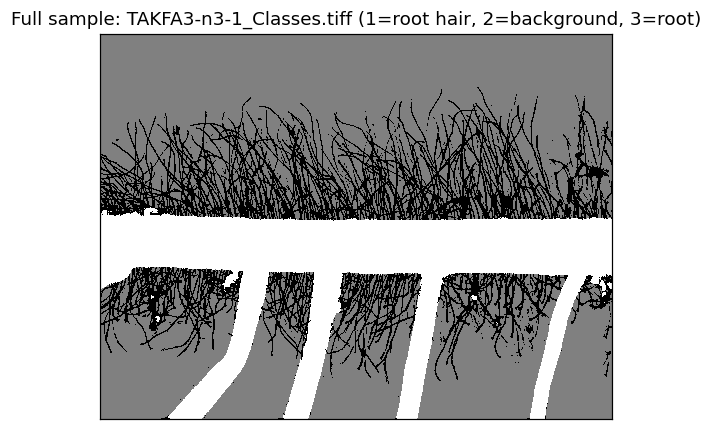

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

data = np.array(plt.imread(SAMPLE))
print("shape:", data.shape, "dtype:", data.dtype)
ids, counts = np.unique(data, return_counts=True)
for i, c in zip(ids, counts):
    print(f"  class id {i}: {c:>10,} pixels")
assert set(np.unique(data)) <= {1, 2, 3}, "unexpected class ids in the sample"

fig, ax = plt.subplots(figsize=(6, 8), dpi=110)
ax.imshow(data, cmap="gray", interpolation="nearest")
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Full sample: TAKFA3-n3-1_Classes.tiff (1=root hair, 2=background, 3=root)")
plt.show()

### Select the deterministic 600x600 demo crop

The full 4080x3072 sample generates ~595,000 candidate hair paths in its densest connected
region; the authors' own container config (`plantit.yaml` in the pinned repo) budgets up to
24 h walltime and 32 GB for such runs, and the full image measurably exceeded 3 h on a Colab
CPU VM without completing. To keep this a hands-on demo, the pipeline below runs on a
**600x600 crop of the same author sample** — selected by a deterministic rule: the window
position (from a coarse 16-px-step grid) that contains the most root-hair (class 1) pixels,
ties broken top-left first. The crop is written next to the sample and verified to contain all
three classes. No pixels are altered; this is input selection, not data modification.

**日本語:** フル画像（4080x3072）は約 59 万件の候補経路が生成され、著者の plantit.yaml 自体が
24 時間 / 32GB を許容する重い処理です。そこで同じサンプル画像から、根毛（クラス 1）ピクセル数が
最大となる 600x600 の領域を決定論的に切り出して使用します（16 px 刻みのグリッドで探索、
同点は左上優先）。ピクセル値は一切変更しません。

Selected window: y0=880, x0=1024, root-hair pixels=187,722
  class id 1:    187,722 pixels in crop
  class id 2:    169,873 pixels in crop
  class id 3:      2,405 pixels in crop


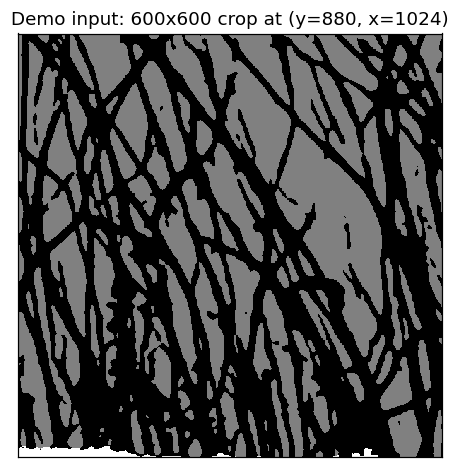

In [ ]:
# Deterministic crop: 600x600 window with the most root-hair pixels (16-px step grid).
import numpy as np
from PIL import Image

CROP = 600
STEP = 16
h, w = data.shape
best = (-1, 0, 0)
for y0 in range(0, h - CROP + 1, STEP):
    for x0 in range(0, w - CROP + 1, STEP):
        n_hair = int(np.count_nonzero(data[y0:y0+CROP, x0:x0+CROP] == 1))
        if n_hair > best[0]:
            best = (n_hair, y0, x0)
n_hair, y0, x0 = best
crop = data[y0:y0+CROP, x0:x0+CROP]
print(f"Selected window: y0={y0}, x0={x0}, root-hair pixels={n_hair:,}")

INPUT = "/content/dirtmu/sample/TAKFA3-n3-1_Classes_crop600.tiff"
Image.fromarray(crop).save(INPUT)
ids, counts = np.unique(crop, return_counts=True)
assert set(np.unique(crop)) == {1, 2, 3}, f"crop missing classes: {dict(zip(ids.tolist(), counts.tolist()))}"
for i, c in zip(ids, counts):
    print(f"  class id {i}: {c:>10,} pixels in crop")

fig, ax = plt.subplots(figsize=(5, 5), dpi=110)
ax.imshow(crop, cmap="gray", interpolation="nearest")
ax.set_xticks([]); ax.set_yticks([])
ax.set_title(f"Demo input: 600x600 crop at (y={y0}, x={x0})")
plt.show()

## 3. Run the authors' pipeline on the demo crop

This executes the authors' pipeline with the demo input and two disclosed settings:
`python3 hairyroots.py -i <crop> -o <out> --id_root 3 --id_roothair 1 --id_background 2
--pixel_size 1.72 -p --n_levels 100`

- **Input:** the 600x600 crop selected above (see section 2 for why).
- **`--n_levels 100`:** the simulated-annealing iteration count defaults to 1000 in
  `hairyroots.py`; the authors' own `plantit.yaml` exposes it with `min: 100, default: 1000,
  max: 2000`. The minimum is used so the demo completes on a free Colab CPU runtime; the
  resulting `Ratio Completeness` in the summary reflects this setting.

Internally (see `hairyroots.py` at the pinned commit) the pipeline: loads the label image →
prunes/cleans the root-hair medial axis (`preprocessing.py`) → segments the medial axis and
builds a branch graph (`segmentation.py`, graph-tool) → enumerates candidate hair paths and
scores their curvature (`candidates.py`) → resolves intersecting hairs by **simulated annealing**
combinatorial optimization (`optimization.py`) → post-processes and measures length/density per
hair (`analysis.py`, `rh_density.py`) → writes CSVs and plots. The only added environment
variable is `MPLBACKEND=Agg` (headless rendering) — mirroring the Qt-backend fix the authors
themselves apply in their Dockerfile. Live progress is streamed from the subprocess; the wall
time of this cell is the pipeline's measured runtime on the demo crop.

**日本語:** 著者のパイプラインを、セクション 2 で選択した 600x600 のデモ用切り出し画像に対して
実行します。`--n_levels 100` は著者の plantit.yaml が文書化する最小値（デフォルト 1000、
Colab CPU で完結させるための明示的な選択）です。内部では 前処理 → med軸セグメント化
（graph-tool）→ 候補経路の列挙・曲率評価 → 焼きなまし法による交差根毛の再構成 →
計量・出力、が行われます。進行状況はそのまま表示されます。

In [ ]:
%%time
import subprocess, os, pathlib

OUT = "/content/dirtmu/out"
pathlib.Path(OUT).mkdir(parents=True, exist_ok=True)
cmd = ["/content/micromamba-bin/bin/micromamba", "run", "-p", "/content/dirtmu-env",
       "python", "hairyroots.py",
       "-i", INPUT,
       "-o", OUT,
       "--id_root", "3", "--id_roothair", "1", "--id_background", "2",
       "--pixel_size", "1.72", "--n_levels", "100", "-p"]

env = dict(os.environ, MPLBACKEND="Agg", MAMBA_ROOT_PREFIX="/content/micromamba")
# Stream the pipeline's own progress lines into the cell output as they appear.
proc = subprocess.Popen(cmd, cwd="/content/dirtmu", env=env,
                        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for line in proc.stdout:
    print(line, end="", flush=True)
proc.wait(timeout=7200)
print("returncode:", proc.returncode)
assert proc.returncode == 0, "author pipeline failed"

print("\nOutputs written to", OUT + ":")
for p in sorted(pathlib.Path(OUT).iterdir()):
    print(f"  {p.name:45s} {p.stat().st_size:>10,} bytes")

/content/dirtmu-env/lib/python3.9/site-packages/graph_tool/all.py:39: RuntimeWarning: Error importing draw module, proceeding nevertheless: libcairomm-1.0.so.1: cannot open shared object file: No such file or directory


  warnings.warn(msg, RuntimeWarning)


/content/dirtmu/hairyroots.py:207: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.


  good_candidates = np.array(all_candidates)[candidate_filter] #[all_candidates[i] for i in candidate_filter]


usage: hairyroots.py [-h] [-i INPUT_PATH] [-o OUTPUT_PATH] [-p]


...

Total time: 01:16:33


**************************************************


                    Finished!                     


**************************************************


returncode: 0

Outputs written to /content/dirtmu/out:
  TAKFA3-n3-1_Classes_crop600_classes.tiff          20,150 bytes
  TAKFA3-n3-1_Classes_crop600_density.png          814,906 bytes
  TAKFA3-n3-1_Classes_crop600_meta.csv               1,068 bytes
  TAKFA3-n3-1_Classes_crop600_outliers.csv             452 bytes
  TAKFA3-n3-1_Classes_crop600_outliers.png          60,933 bytes
  TAKFA3-n3-1_Classes_crop600_roothairs.csv          1,814 bytes
  TAKFA3-n3-1_Classes_crop600_roothairs.png        377,064 bytes
  TAKFA3-n3-1_Classes_crop600_summary.csv              478 bytes
CPU times: user 546 ms, sys: 104 ms, total: 650 ms
Wall time: 1h 16min 38s


## 4. Results

The run writes one row per reconstructed root hair (`..._roothairs.csv`), an image-level summary
(`..._summary.csv`), rejected candidates (`..._outliers.csv`), the simulated-annealing and timing
record (`..._meta.csv`), and overlay/density plots. Length columns are in **µm** (pixel size
1.72 µm/px). The tables below are read from the actual CSVs written by the run above.

**日本語:** 根毛 1 本ずつの計量表、画像単位のサマリ、除外候補、焼きなましのメタデータ、
およびオーバーレイ図・密度図が出力されます。長さの単位は µm（1 px = 1.72 µm）です。
以下の表は上の実行が書き出した CSV をそのまま読み込んだものです。

In [ ]:
import pandas as pd, os

experiment = os.path.splitext(os.path.basename(INPUT))[0]
summary = pd.read_csv(f"{OUT}/{experiment}_summary.csv")
hairs = pd.read_csv(f"{OUT}/{experiment}_roothairs.csv")
outliers = pd.read_csv(f"{OUT}/{experiment}_outliers.csv")

print(f"Reconstructed root hairs: {len(hairs)} (rejected outliers: {len(outliers)})")
display(summary.T.rename(columns={summary.index[0]: experiment}))
print()
display(hairs.head(10))

Reconstructed root hairs: 11 (rejected outliers: 2)


,TAKFA3-n3-1_Classes_crop600
Area Background (pxl),171095.000000
Area Root (pxl),1985.000000
Area Roothair (pxl),186914.000000
Edge Length Bottom (mu),0.000000
Edge Length Top (mu),232.606059
Edge Length Total (mu):,232.606059
Length Inliers (mu),11446.237100
Length Outliers (mu),57.444687
Ratio Completeness,0.410680
RH Count Bottom,0.000000


,length_mu,curvature_total,curvature_mean,curvature_median,curvature_min,curvature_max,diameter_mu_mean,diameter_mu_median,diameter_mu_min,diameter_mu_max,root_classes,root_positions
0,868.556120,2.900786,0.005829,0.003346,0.000017,0.035434,27.886479,27.520000,14.594684,51.714540,main,top
1,1080.392306,5.147304,0.008280,0.003383,0.000007,0.273551,30.586432,22.551484,6.880000,106.634211,main,top
2,879.110323,1.992099,0.003950,0.002162,0.000003,0.024778,29.671114,20.640000,12.403096,106.634211,main,top
3,3296.628505,11.337695,0.005945,0.002395,0.000009,0.433101,35.809103,32.543800,6.880000,113.988126,lateral,other
4,1107.314040,4.175244,0.006590,0.004305,0.000005,0.043373,29.271719,20.058475,10.320000,106.634211,lateral,other
5,1133.301643,3.457103,0.005388,0.003735,0.000015,0.042106,30.779561,26.867259,3.440000,72.240000,lateral,other
6,2393.055001,11.486242,0.008399,0.003041,0.000002,0.219679,30.509326,26.198259,3.440000,113.988126,lateral,other
7,510.663895,3.450958,0.011782,0.007596,0.000013,0.059874,42.327209,38.460369,4.864895,106.634211,main,top
8,229.768757,0.339089,0.002577,0.002007,0.000021,0.008164,29.808104,22.026747,3.440000,72.973420,main,top
9,126.449700,1.381334,0.026502,0.029828,0.000677,0.063523,32.359287,24.565333,20.640000,70.162509,main,top


### Distribution of measured root hair lengths

A small additional graph created for this notebook (not an author figure): the distribution of
the reconstructed per-hair lengths in µm, taken from the per-hair table above for this single
sample.

**日本語:** このノートブック用に追加した補助グラフ（著者の図ではありません）：
再構成された根毛 1 本ずつの長さ（µm）の分布を表示します。

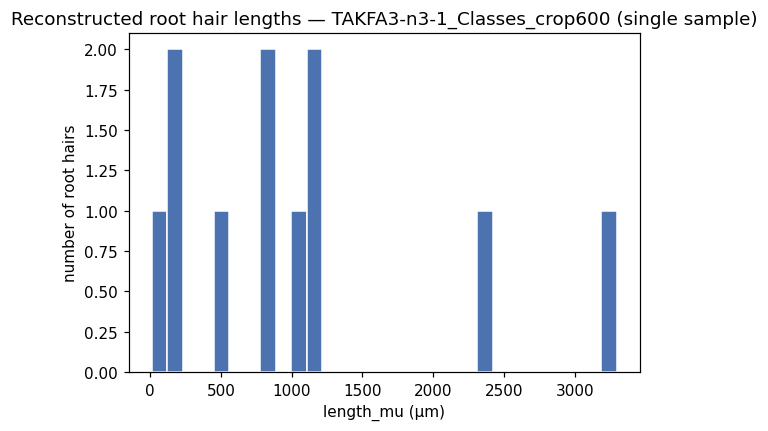

In [ ]:
import matplotlib.pyplot as plt

length_col = [c for c in hairs.columns if "length" in c.lower()]
assert length_col, f"no length column found in {list(hairs.columns)}"
vals = pd.to_numeric(hairs[length_col[0]], errors="coerce").dropna()

fig, ax = plt.subplots(figsize=(6, 4), dpi=110)
ax.hist(vals, bins=30, color="#4C72B0", edgecolor="white")
ax.set_xlabel(f"{length_col[0]} (µm)")
ax.set_ylabel("number of root hairs")
ax.set_title(f"Reconstructed root hair lengths — {experiment} (single sample)")
plt.show()

### Overlay: reconstructed hairs drawn on the input image

The pipeline's own plot (`..._roothairs.png`, produced by `rh_plot.plot_results`): the grayscale
input with each **reconstructed individual root hair** drawn as a thin colored curve. This is
the measurement overlay of this reproduction — the algorithm's output on the real input, not a
paper figure. `..._density.png` (root hair density along the root, from `rh_density.py`) and
the rejected-candidate overlay `..._outliers.png` follow.

**日本語:** パイプライン自身が出力した図です。グレースケールの入力画像に、再構成された
個々の根毛を細い色付き曲線で重ねています。これは本実行の測定オーバーレイであり、
論文の図そのものではありません。続いて密度図・除外候補図を表示します。

_roothairs.png


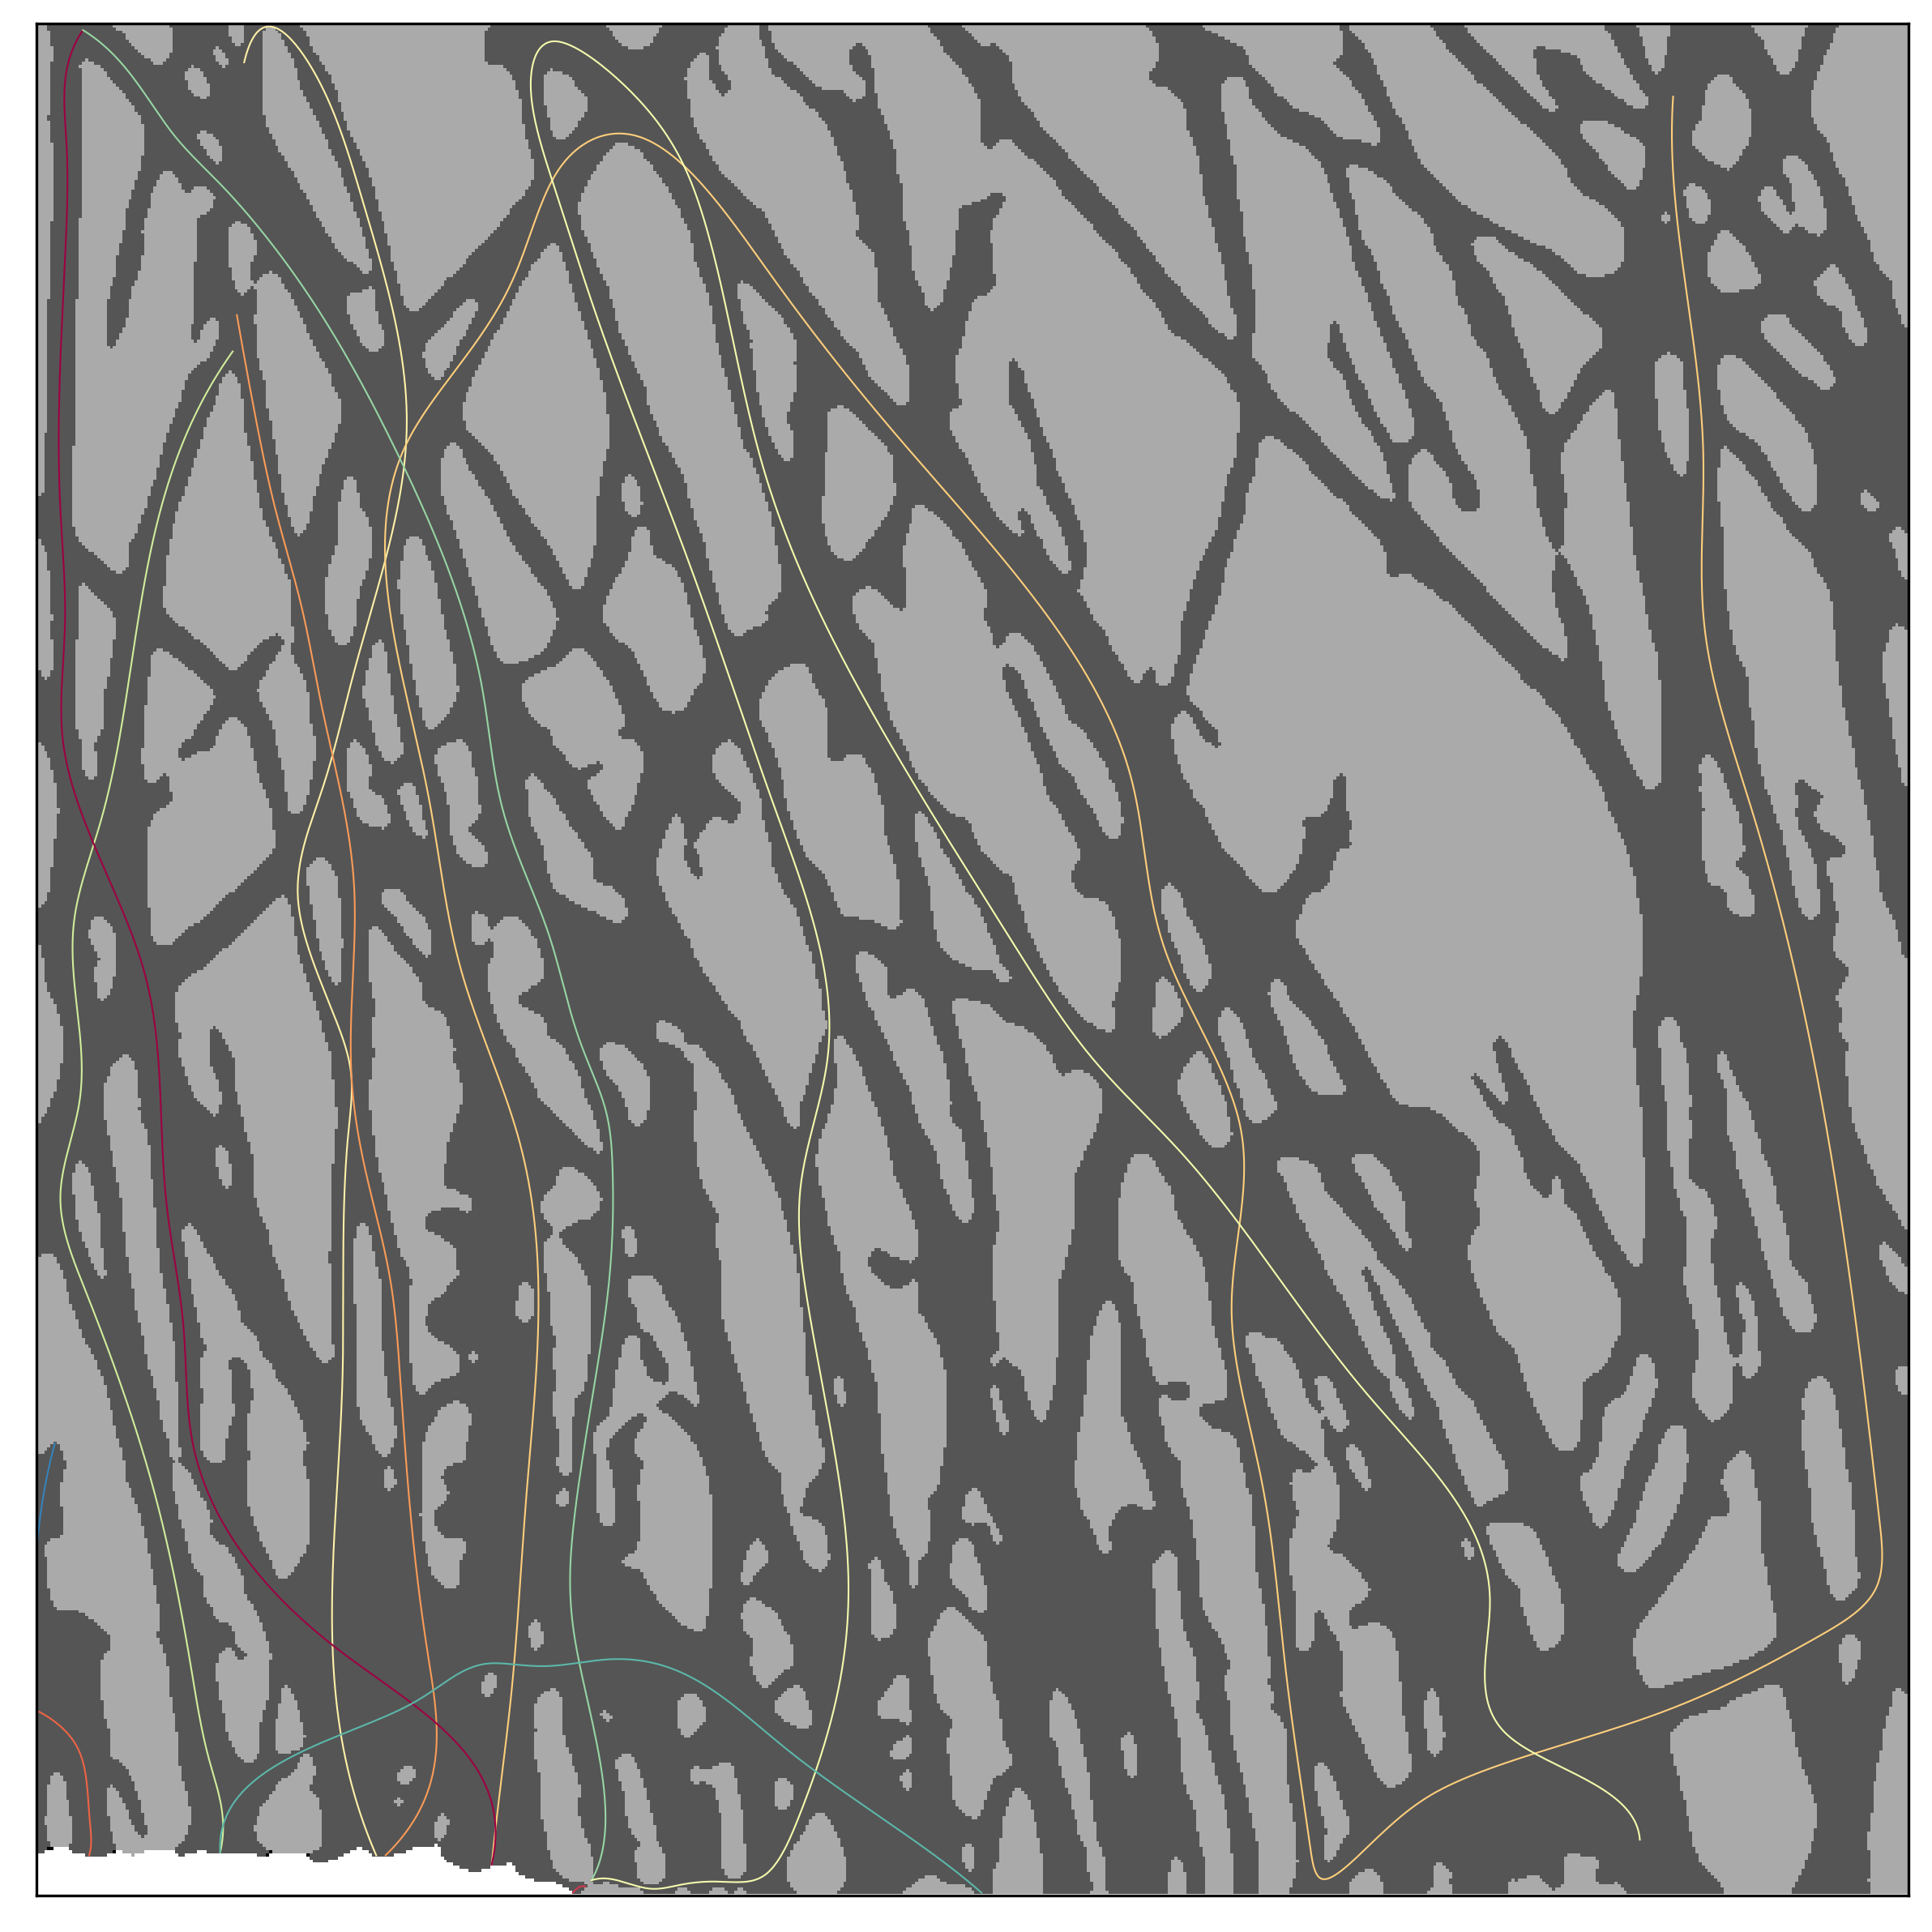

_density.png


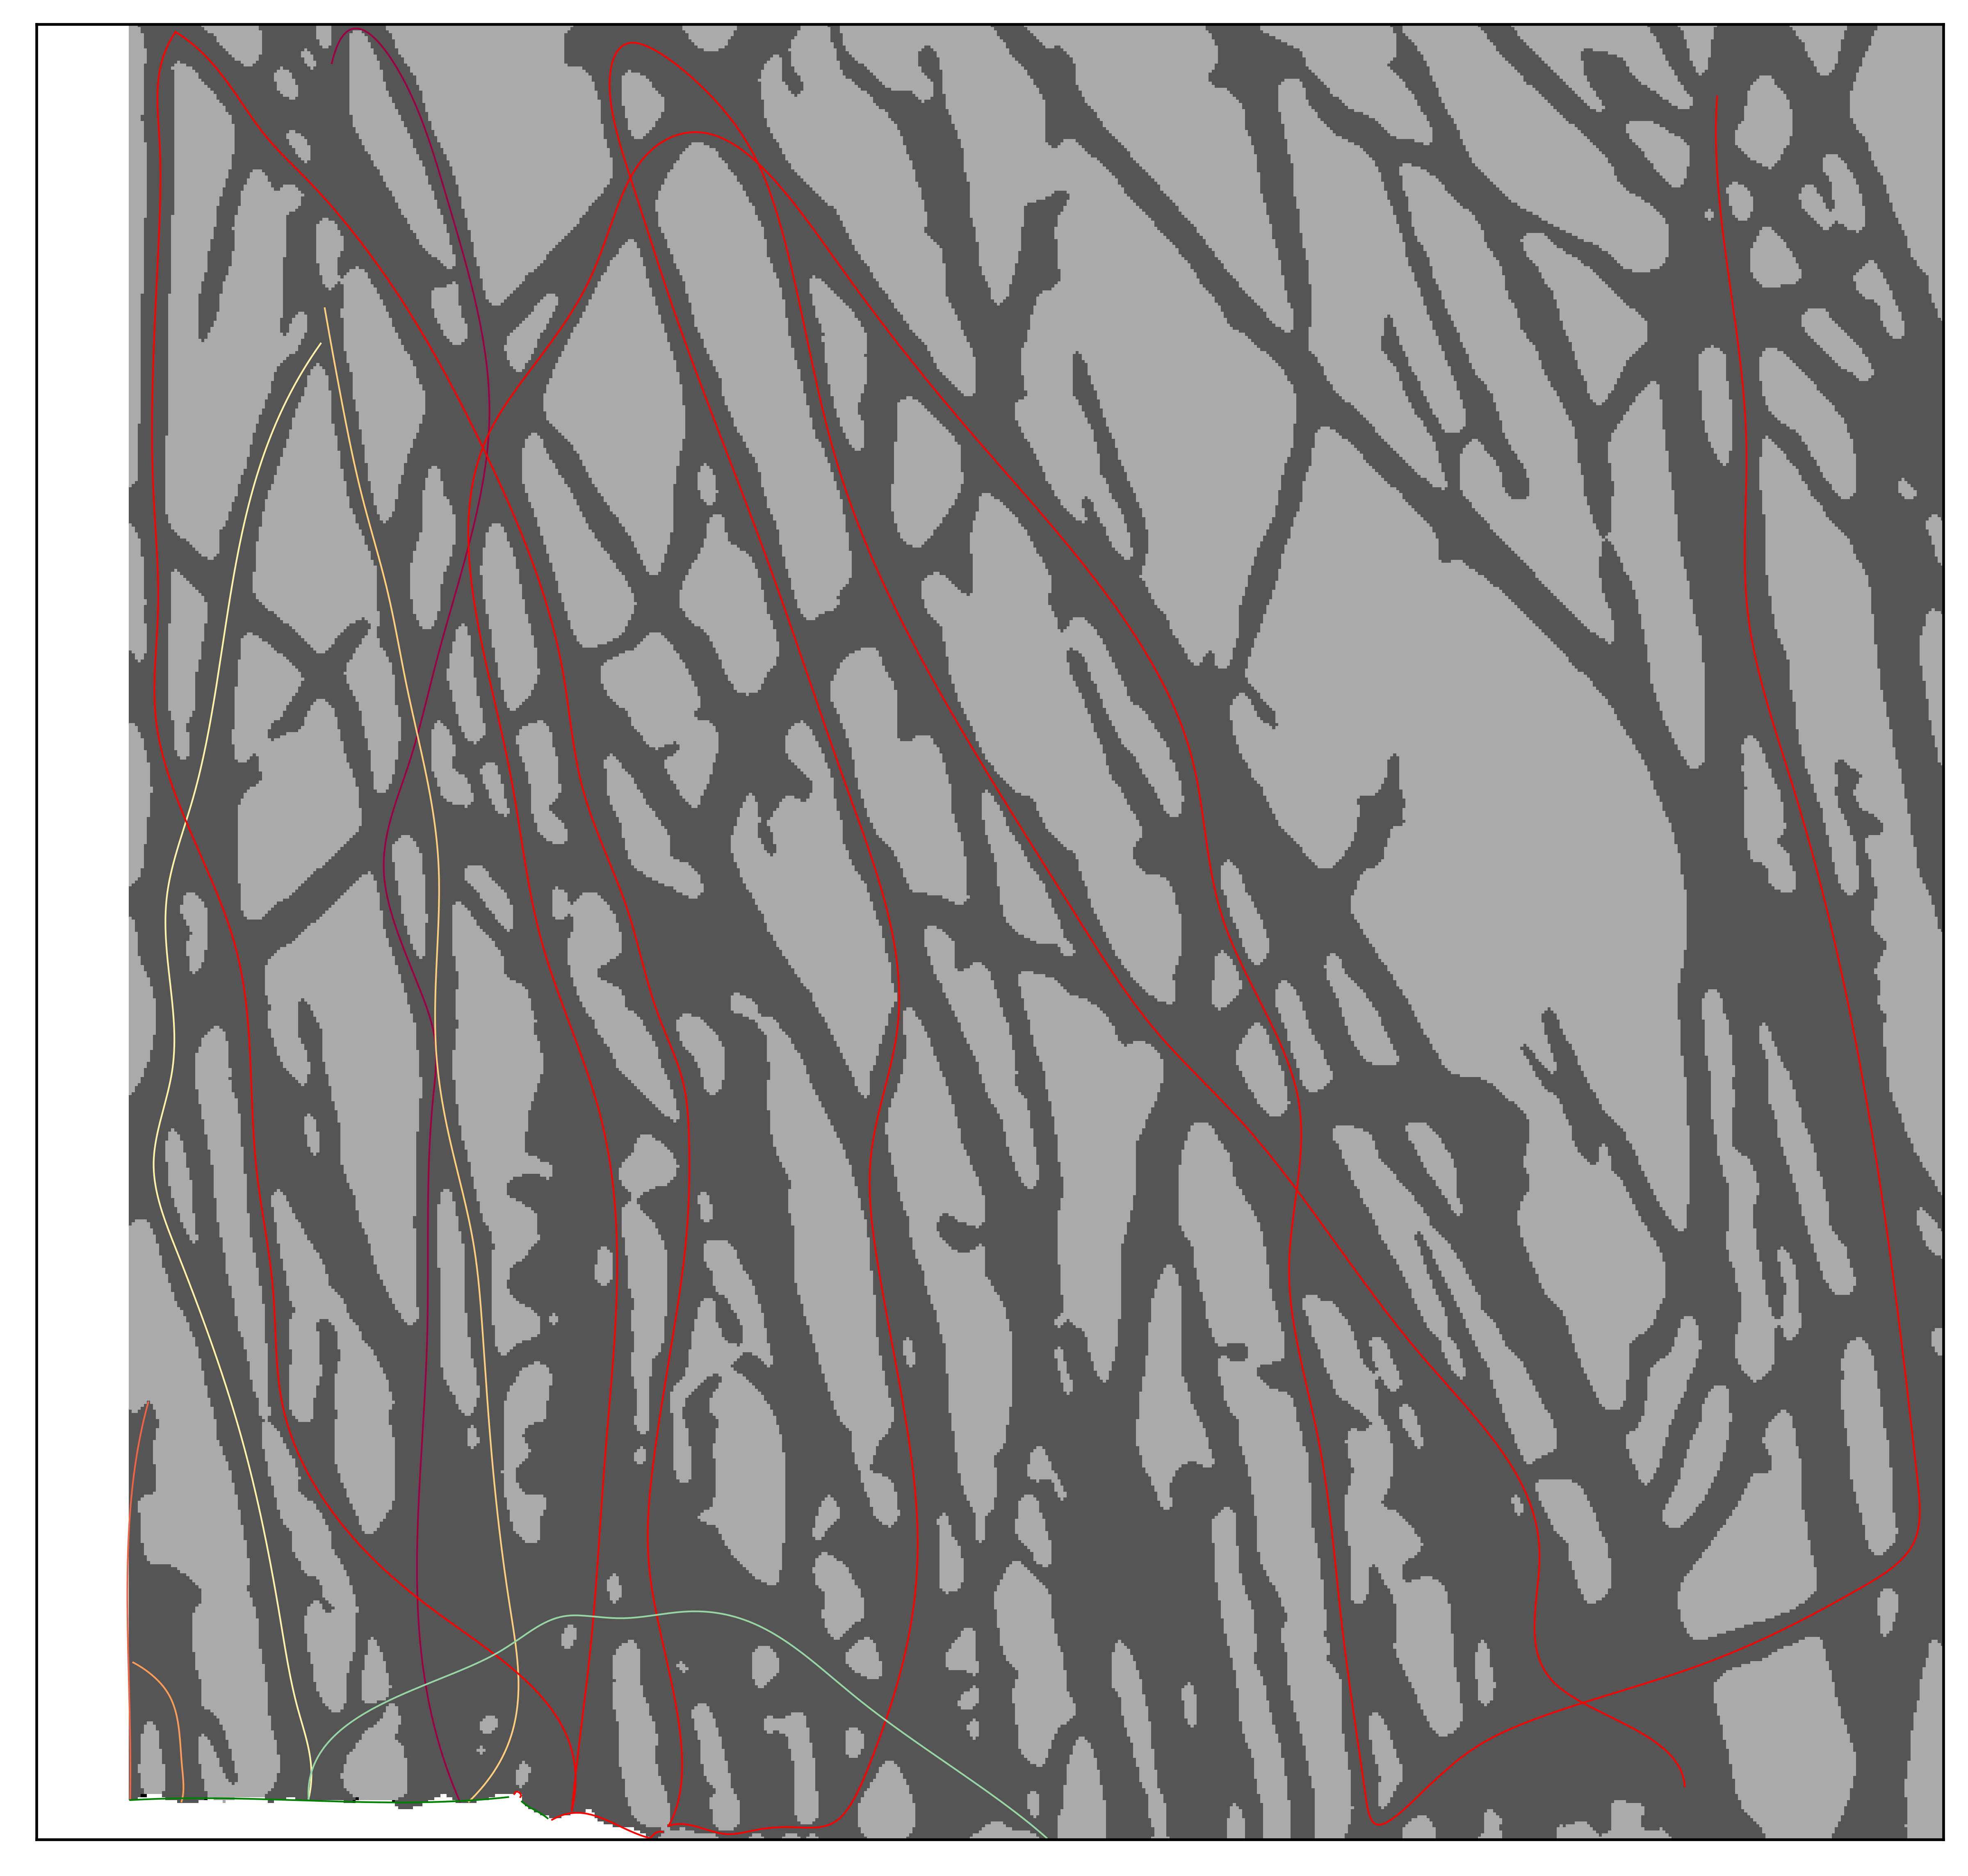

_outliers.png


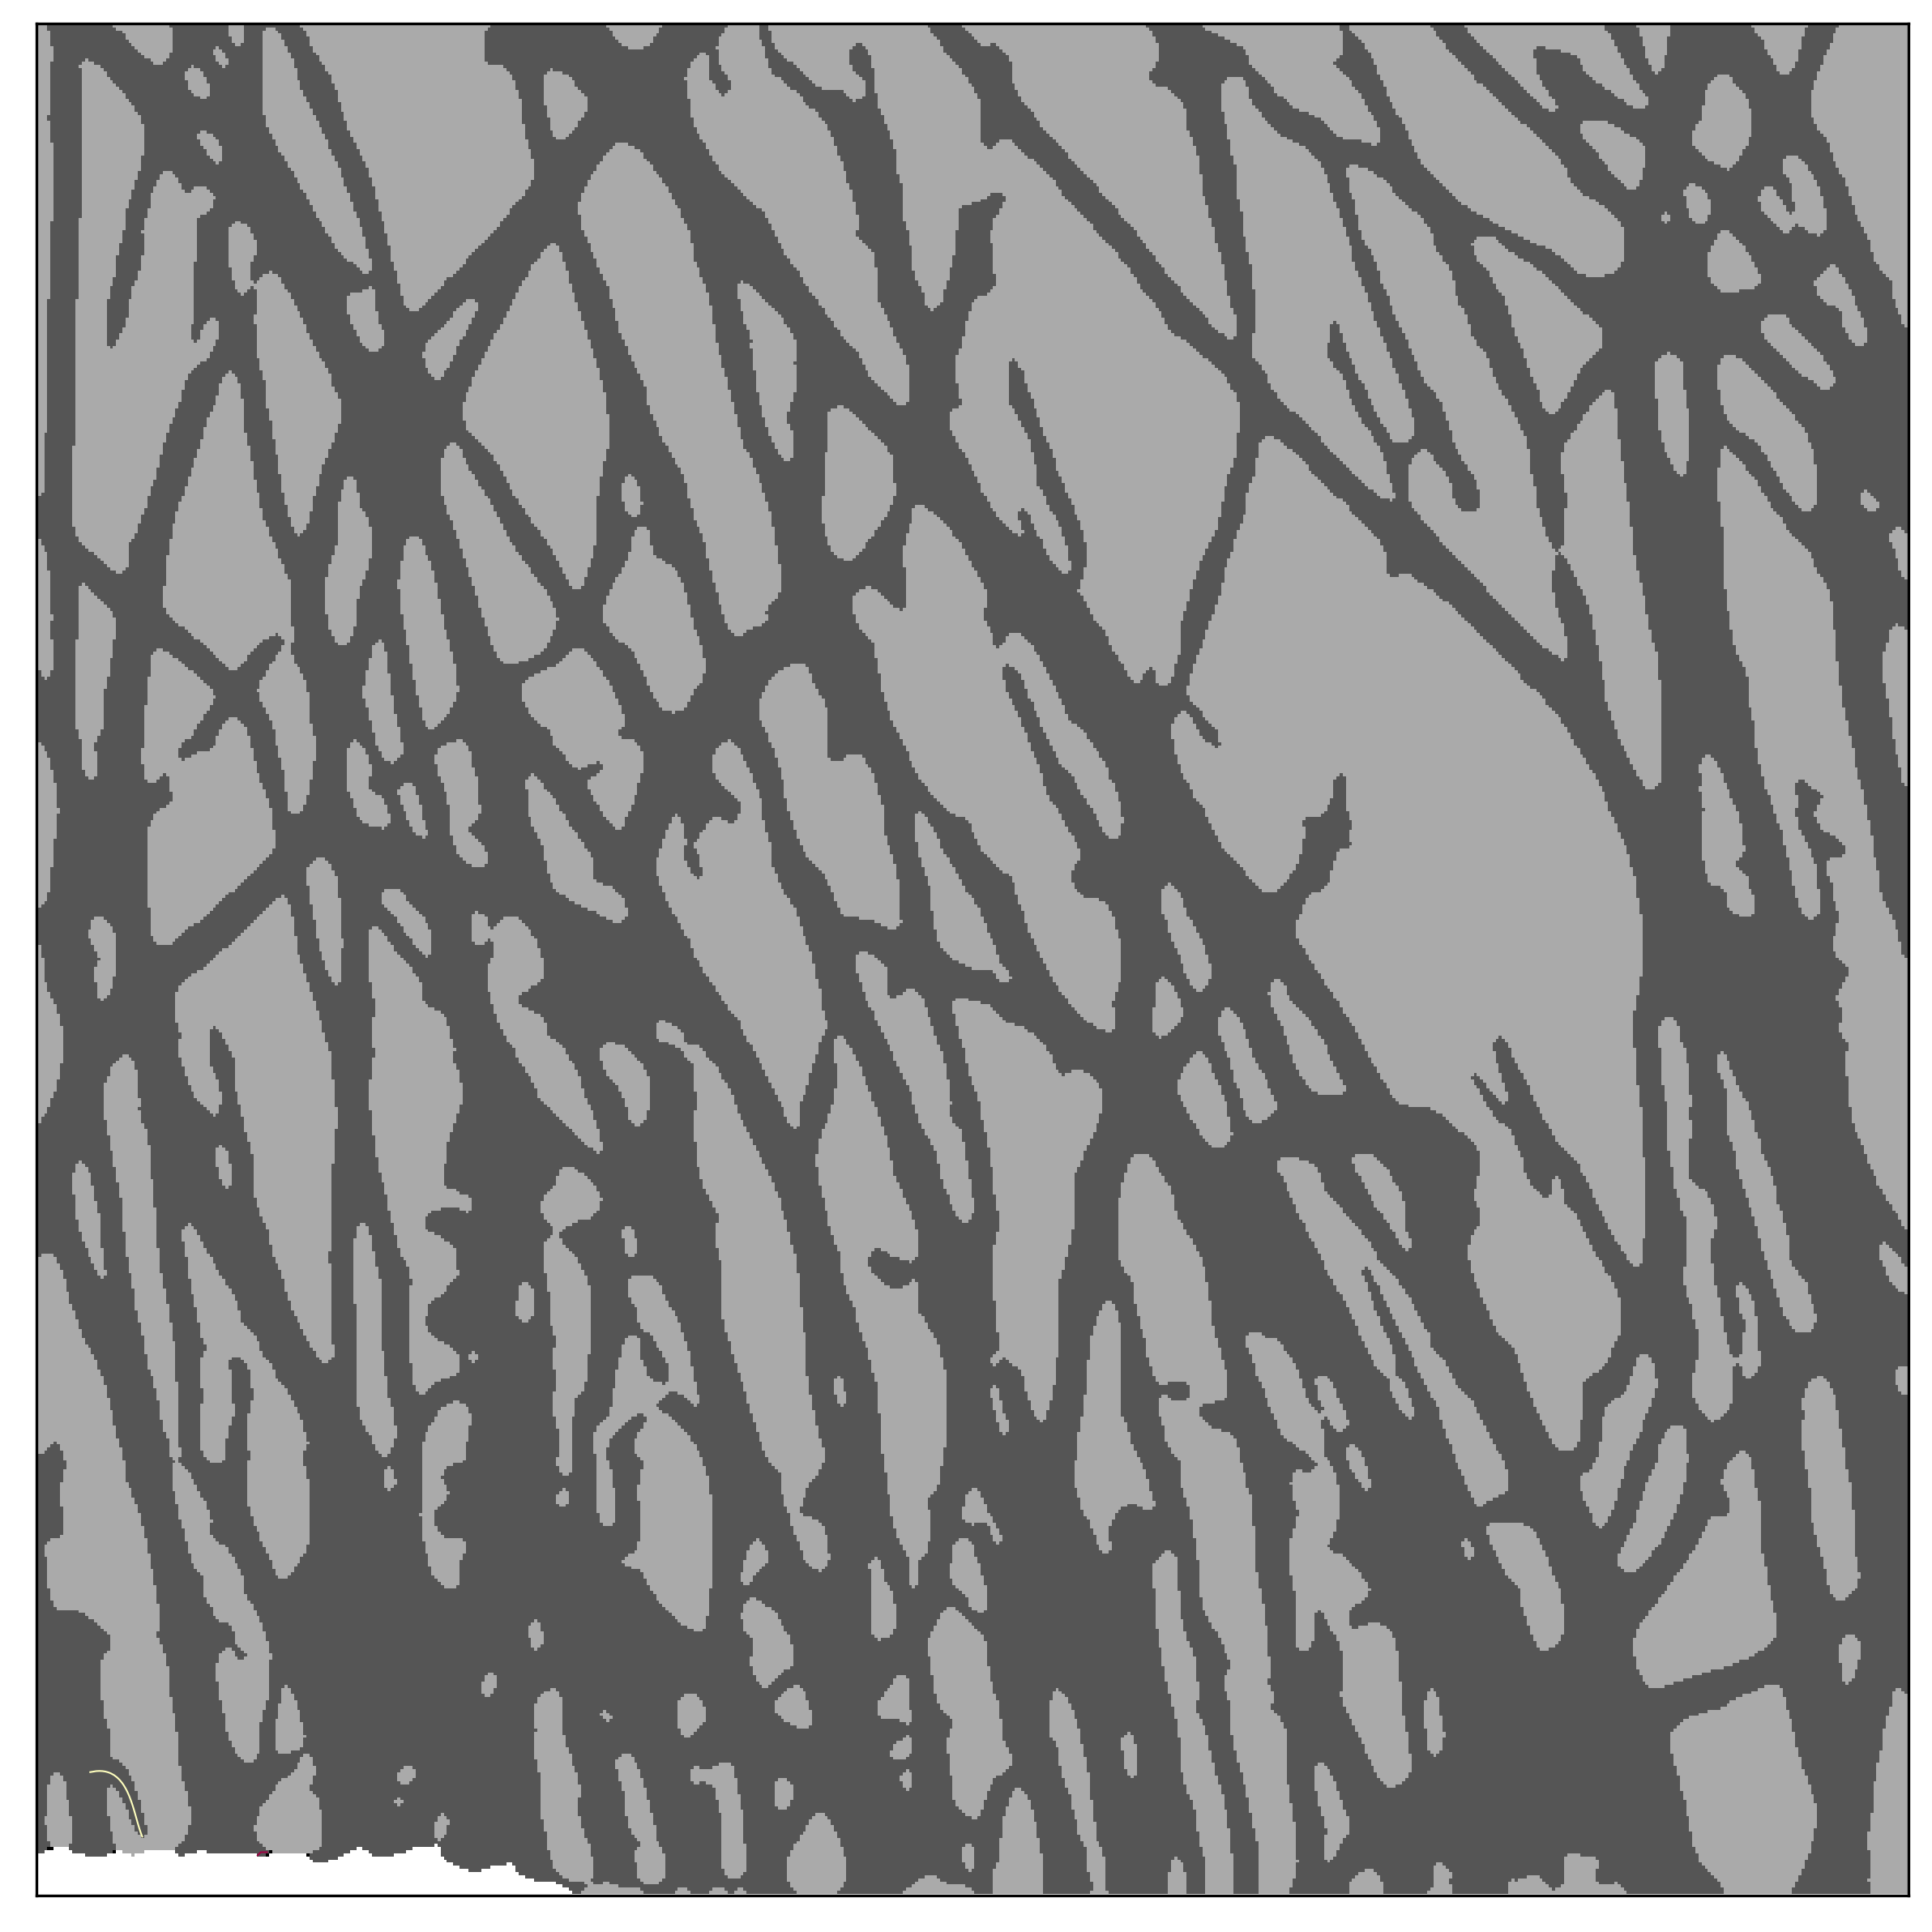

In [ ]:
from IPython.display import Image, display

for name in ["_roothairs.png", "_density.png", "_outliers.png"]:
    print(name)
    display(Image(filename=f"{OUT}/{experiment}{name}", width=560))

## 5. Interpretation and limitations

- **What was executed:** the authors' released DIRT/mu 1.1 reconstruction-and-measurement
  pipeline, byte-for-byte from pinned commit `d54aac0c...`, on a 600x600 crop of their own
  sample classified image, with their documented parameters — except two disclosed settings:
  the demo crop itself (section 2) and `--n_levels 100` (the authors' documented minimum;
  the default 1000 exceeds a practical Colab session even for the crop's parent image).
  On this real maize region it reconstructs the individual root hairs, reports per-hair
  lengths (µm), image-level summary statistics (hair count, completeness ratio, class areas,
  densities), and the overlay/density plots shown above.
- **What this does not verify:** the random-forest classification stage (no released
  classifier/training set — out of scope), the paper's validation across three maize cultivars
  under P/N/K stress (no public dataset release), and the published automatic-vs-manual
  correlations (single crop only). A one-region run is a hands-on demonstration, not a
  dataset-level reproduction. The reduced `n_levels` may also lower reconstruction completeness
  versus the authors' default; the summary's `Ratio Completeness` value reflects this setting.
- **Faithfulness:** author code was not modified. Adaptations are orchestration and input
  selection only: the authors' conda env built via micromamba (as in their Dockerfile),
  `MPLBACKEND=Agg` for headless rendering (the same Qt issue the authors fix in their own
  Dockerfile), the deterministic crop, and the disclosed `--n_levels 100`.

**日本語:** 実行したのは著者公開コードそのもの（ピン留めコミット、改変なし）であり、
同梱サンプル画像から決定論的に切り出した 600x600 領域に対する根毛の再構成・計量です。
`--n_levels` は著者が plantit.yaml で文書化している最小値 100 を使用しました
（デフォルト 1000 は Colab CPU で数時間以上かかるため）。完了率（Ratio Completeness）は
この設定を反映します。分類段階（分類器未公開）、3 品種 × P/N/K ストレスの検証データ
（非公開）、自動 vs 手作業の相関の検証は対象外です。1 領域の実行は論文結果全体の
検証ではありません。

## Validation record and references

- Validated top-to-bottom on a fresh Google Colab **CPU** runtime, 2026-10-29 (see the saved
  cell outputs in this notebook; timings are printed by the cells above).
- Paper: P. Pietrzyk, N. Phan-Udom, C. Chutoe, P. Saengwilai, A. Bucksch,
  *Automatic root hair measurement to quantify abiotic stresses in microscopy images*,
  ESSOAr preprint, DOI [10.1002/essoar.10508328.1](https://doi.org/10.1002/essoar.10508328.1).
- Code: [Computational-Plant-Science/DIRTmu](https://github.com/Computational-Plant-Science/DIRTmu)
  v1.1, commit `d54aac0c38e194a84363496d8f17f9a0016d3bdc`, BSD-3-Clause. Container:
  [computationalplantscience/dirtmu](https://hub.docker.com/r/computationalplantscience/dirtmu).
- Related later version (reference for the code identity): Pietrzyk & Bucksch, DIRT/mu,
  bioRxiv 2024.01.18.576310; `plantit.yaml` in the pinned repo cites ESSOAr DOI
  10.1002/essoar.10508833.1.
- Sample input: `sample/TAKFA3-n3-1_Classes.tiff` shipped in the pinned repository.

**日本語:** 検証は 2026-10-29 に新規 Colab CPU ランタイムで全体を最初から実行し、
その保存済み出力で確認しています。参照文献・コードのバージョンは上記のとおりです。